In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

# Project directory
BASE_DIR = Path.cwd().parent

# CSV path
DATA_PATH = BASE_DIR / "data" / "raw" / "transactions.csv"

# Load CSV
df = pd.read_csv(DATA_PATH)

print("CSV loaded successfully!")

print("Shape:", df.shape)

display(df.head())

CSV loaded successfully!
Shape: (5000, 8)


,transaction_amount,transaction_hour,transaction_type,account_balance,channel,merchant_category,account_type,is_fraud
0,5158.96,13,IMPS,21117.51,ATM,Entertainment,Savings,0
1,458.53,7,POS,122196.34,Web,Entertainment,Current,0
2,11508.17,2,RTGS,63586.25,Web,Healthcare,Savings,1
3,16204.05,10,UPI,277426.02,Mobile_App,Entertainment,Savings,0
4,100.00,6,ATM,236763.85,Mobile_App,Travel,Savings,0


In [2]:
# Dataset information

print("Dataset Information:")
print("-" * 40)

df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_amount  5000 non-null   float64
 1   transaction_hour    5000 non-null   int64  
 2   transaction_type    5000 non-null   str    
 3   account_balance     5000 non-null   float64
 4   channel             5000 non-null   str    
 5   merchant_category   5000 non-null   str    
 6   account_type        5000 non-null   str    
 7   is_fraud            5000 non-null   int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 445.3 KB

Missing Values:
transaction_amount    0
transaction_hour      0
transaction_type      0
account_balance       0
channel               0
merchant_category     0
account_type          0
is_fraud              0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,transaction_amount,transaction_hour,account_balance,is_fraud
count,5000.000000,5000.000000,5.000000e+03,5000.000000
mean,14367.747220,11.412000,6.845487e+04,0.050000
std,49885.050596,6.925189,9.635999e+04,0.217967
min,100.000000,0.000000,6.201100e+02,0.000000
25%,857.897500,6.000000,1.758560e+04,0.000000
50%,2958.715000,11.000000,3.765159e+04,0.000000
75%,9285.832500,17.000000,7.926611e+04,0.000000
max,1000000.000000,23.000000,1.815732e+06,1.000000


In [3]:
# Check fraud distribution

fraud_counts = df["is_fraud"].value_counts()

print("Transaction Distribution:")
print(fraud_counts)

print("\nPercentage Distribution:")
print(
    df["is_fraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFraud Transactions:", (df["is_fraud"] == 1).sum())
print("Genuine Transactions:", (df["is_fraud"] == 0).sum())

Transaction Distribution:
is_fraud
0    4750
1     250
Name: count, dtype: int64

Percentage Distribution:
is_fraud
0    95.0
1     5.0
Name: proportion, dtype: float64

Fraud Transactions: 250
Genuine Transactions: 4750


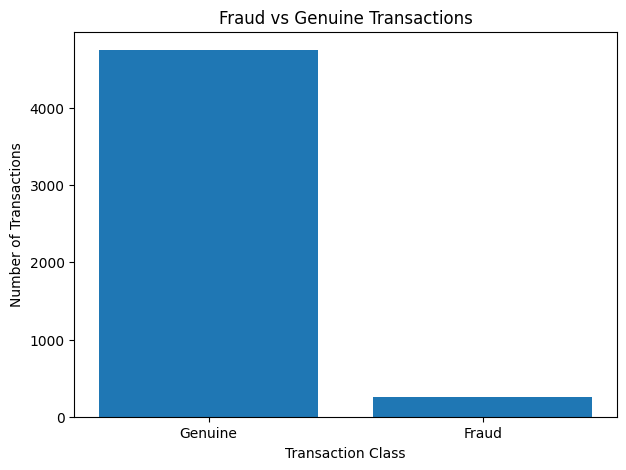

In [4]:
import matplotlib.pyplot as plt

fraud_counts = df["is_fraud"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Genuine", "Fraud"],
    [fraud_counts[0], fraud_counts[1]]
)

plt.title("Fraud vs Genuine Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

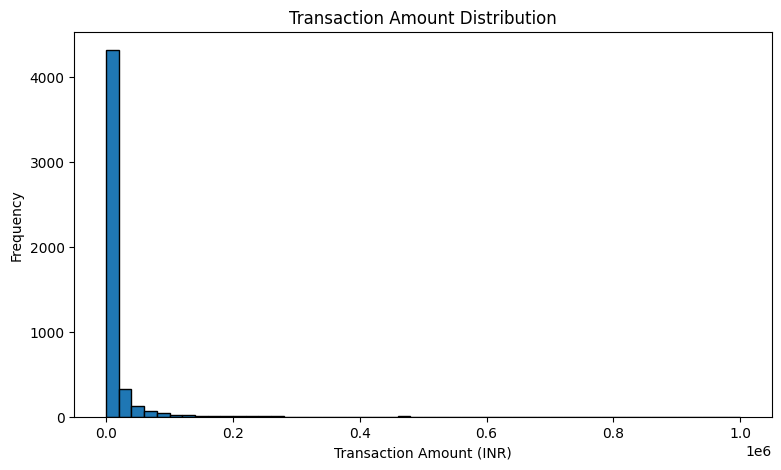

In [5]:
# Transaction amount distribution

plt.figure(figsize=(9, 5))

plt.hist(
    df["transaction_amount"],
    bins=50,
    edgecolor="black"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")

plt.show()

<Figure size 800x500 with 0 Axes>

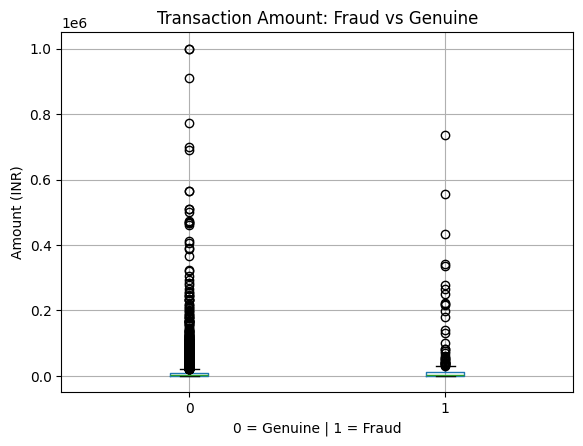

In [6]:
# Compare transaction amounts

plt.figure(figsize=(8, 5))

df.boxplot(
    column="transaction_amount",
    by="is_fraud"
)

plt.title("Transaction Amount: Fraud vs Genuine")
plt.suptitle("")
plt.xlabel("0 = Genuine | 1 = Fraud")
plt.ylabel("Amount (INR)")

plt.show()

In [7]:
# Fraud rate by transaction hour

hour_analysis = df.groupby("transaction_hour").agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

hour_analysis["fraud_rate"] *= 100

display(hour_analysis.round(2))

,total_transactions,fraud_transactions,fraud_rate
transaction_hour,,,
0,219,9,4.11
1,214,9,4.21
2,218,12,5.50
3,222,16,7.21
4,188,13,6.91
5,182,9,4.95
6,219,10,4.57
7,217,9,4.15
8,231,10,4.33


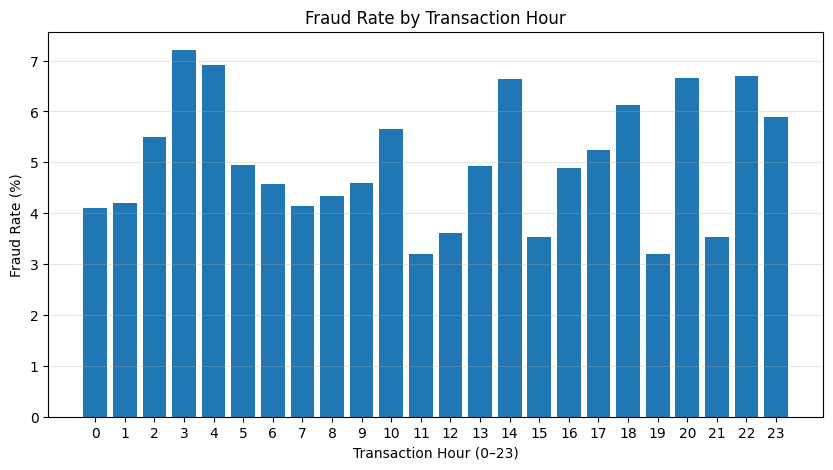

In [8]:
plt.figure(figsize=(10, 5))

plt.bar(
    hour_analysis.index,
    hour_analysis["fraud_rate"]
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour (0–23)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [9]:
# Fraud analysis by transaction type

type_analysis = df.groupby("transaction_type").agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

type_analysis["fraud_rate"] *= 100

display(type_analysis.sort_values(
    by="fraud_rate",
    ascending=False
).round(2))

,total_transactions,fraud_transactions,fraud_rate
transaction_type,,,
ATM,732,62,8.47
RTGS,682,54,7.92
IMPS,735,34,4.63
Credit_Card,698,27,3.87
UPI,723,27,3.73
NEFT,730,26,3.56
POS,700,20,2.86


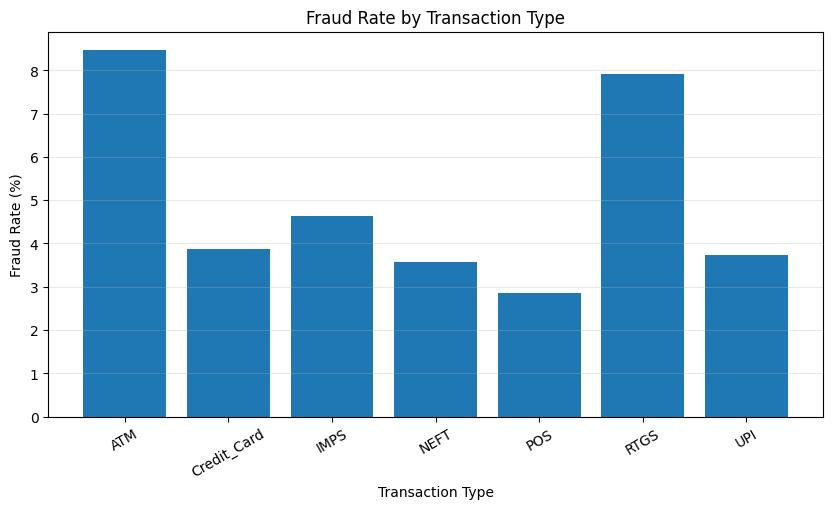

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    type_analysis.index,
    type_analysis["fraud_rate"]
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [11]:
# Fraud analysis by transaction channel

channel_analysis = df.groupby("channel").agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

channel_analysis["fraud_rate"] *= 100

display(
    channel_analysis.sort_values(
        by="fraud_rate",
        ascending=False
    ).round(2)
)

,total_transactions,fraud_transactions,fraud_rate
channel,,,
Web,975,58,5.95
Mobile_App,982,52,5.30
ATM,1003,51,5.08
Branch,991,50,5.05
POS_Terminal,1049,39,3.72


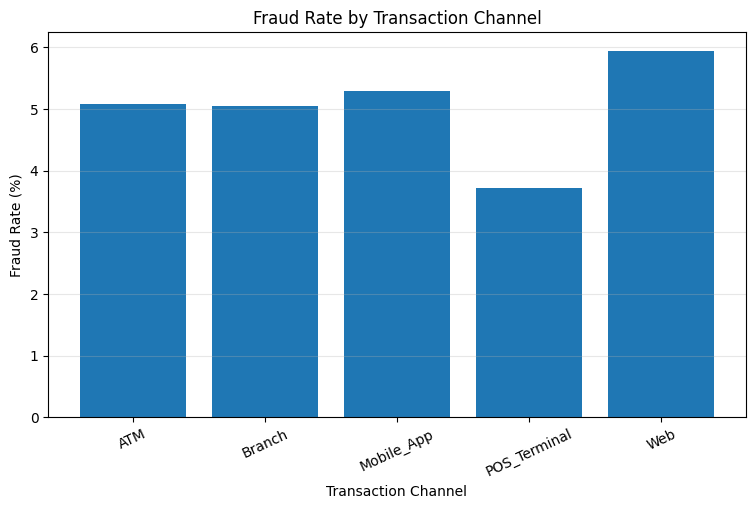

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
    channel_analysis.index,
    channel_analysis["fraud_rate"]
)

plt.title("Fraud Rate by Transaction Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [13]:
# Account balance comparison

balance_analysis = df.groupby("is_fraud")["account_balance"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(balance_analysis.round(2))

,count,mean,median,min,max
is_fraud,,,,,
0,4750,68665.48,37602.79,620.11,1815731.66
1,250,64453.22,38840.01,1725.25,598263.79


<Figure size 800x500 with 0 Axes>

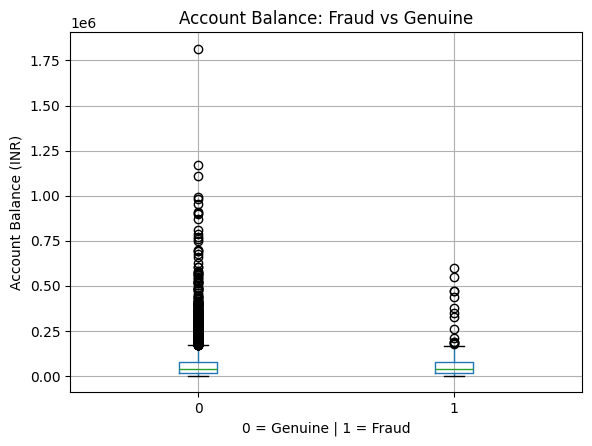

In [14]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="account_balance",
    by="is_fraud"
)

plt.title("Account Balance: Fraud vs Genuine")
plt.suptitle("")
plt.xlabel("0 = Genuine | 1 = Fraud")
plt.ylabel("Account Balance (INR)")

plt.show()

In [15]:
# Fraud analysis by merchant category

merchant_analysis = df.groupby("merchant_category").agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

merchant_analysis["fraud_rate"] *= 100

display(
    merchant_analysis.sort_values(
        by="fraud_rate",
        ascending=False
    ).round(2)
)

,total_transactions,fraud_transactions,fraud_rate
merchant_category,,,
Healthcare,608,40,6.58
Shopping,592,33,5.57
Education,614,33,5.37
Travel,620,32,5.16
Utilities,647,32,4.95
Entertainment,652,29,4.45
Food,643,26,4.04
Electronics,624,25,4.01


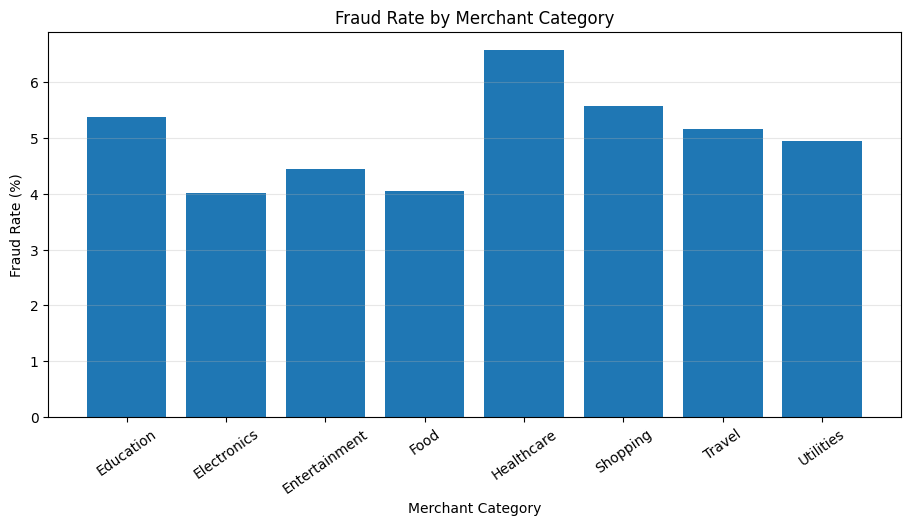

In [16]:
plt.figure(figsize=(11, 5))

plt.bar(
    merchant_analysis.index,
    merchant_analysis["fraud_rate"]
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [17]:
# Create transaction conditions

df["is_night"] = df["transaction_hour"].isin(
    [22, 23, 0, 1, 2, 3, 4, 5]
)

df["is_high_amount"] = (
    df["transaction_amount"] > 200000
)

# Analyze fraud rate

rule_analysis = df.groupby(
    ["is_night", "is_high_amount"]
).agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

rule_analysis["fraud_rate"] *= 100

display(rule_analysis.round(2))

total_transactions  fraud_transactions  fraud_rate
is_night is_high_amount                                                    
False    False                         3319                 152        4.58
         True                            38                   5       13.16
True     False                         1627                  87        5.35
         True                            16                   6       37.50

In [18]:
print("Total transactions:", len(df))

print("Total fraud cases:", df["is_fraud"].sum())

print(
    "Fraud percentage:",
    round(df["is_fraud"].mean() * 100, 2),
    "%"
)

print("\nFraud cases by transaction condition:")

display(
    df.groupby(["is_night", "is_high_amount"])["is_fraud"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total",
        "sum": "fraud",
        "mean": "fraud_rate"
    })
)

Total transactions: 5000
Total fraud cases: 250
Fraud percentage: 5.0 %

Fraud cases by transaction condition:


total  fraud  fraud_rate
is_night is_high_amount                          
False    False            3319    152    0.045797
         True               38      5    0.131579
True     False            1627     87    0.053473
         True               16      6    0.375000

In [19]:
# Final dataset validation

print("========== DATASET VALIDATION ==========")

# 1. Dataset shape
print("\nDataset Shape:", df.shape)

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 4. Invalid transaction amounts
print(
    "\nInvalid Amounts:",
    (df["transaction_amount"] <= 0).sum()
)

# 5. Invalid transaction hours
print(
    "Invalid Hours:",
    (~df["transaction_hour"].between(0, 23)).sum()
)

# 6. Invalid fraud labels
print(
    "Invalid Fraud Labels:",
    (~df["is_fraud"].isin([0, 1])).sum()
)

# 7. Fraud distribution
print("\nFraud Distribution:")
print(df["is_fraud"].value_counts())

========== DATASET VALIDATION ==========

Dataset Shape: (5000, 10)

Missing Values:
transaction_amount    0
transaction_hour      0
transaction_type      0
account_balance       0
channel               0
merchant_category     0
account_type          0
is_fraud              0
is_night              0
is_high_amount        0
dtype: int64

Duplicate Records: 0

Invalid Amounts: 0
Invalid Hours: 0
Invalid Fraud Labels: 0

Fraud Distribution:
is_fraud
0    4750
1     250
Name: count, dtype: int64


In [20]:
# Select input features

FEATURES = [
    "transaction_amount",
    "transaction_hour",
    "transaction_type",
    "account_balance",
    "channel"
]

TARGET = "is_fraud"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected Features:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts())

Feature shape: (5000, 5)
Target shape: (5000,)

Selected Features:
   transaction_amount  transaction_hour transaction_type  account_balance  \
0             5158.96                13             IMPS         21117.51   
1              458.53                 7              POS        122196.34   
2            11508.17                 2             RTGS         63586.25   
3            16204.05                10              UPI        277426.02   
4              100.00                 6              ATM        236763.85   

      channel  
0         ATM  
1         Web  
2         Web  
3  Mobile_App  
4  Mobile_App  

Target Distribution:
is_fraud
0    4750
1     250
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Split features and target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Feature groups
numeric_features = [
    "transaction_amount",
    "transaction_hour",
    "account_balance"
]

categorical_features = [
    "transaction_type",
    "channel"
]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create model pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# Predictions
y_pred = logistic_model.predict(X_test)

# Fraud probabilities
y_probability = logistic_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Fraud Probabilities:")
print(y_probability[:10].round(4))

Logistic Regression trained successfully!

First 10 Predictions:
[0 1 0 0 1 1 1 1 0 0]

First 10 Fraud Probabilities:
[0.4622 0.6098 0.356  0.3749 0.6153 0.6044 0.639  0.635  0.3048 0.4224]


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# PR-AUC
pr_auc = average_precision_score(y_test, y_probability)

print("\nPR-AUC:", pr_auc)

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC:", roc_auc)

Accuracy: 0.673

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.68      0.80       950
           1       0.07      0.48      0.13        50

    accuracy                           0.67      1000
   macro avg       0.52      0.58      0.46      1000
weighted avg       0.92      0.67      0.77      1000


Confusion Matrix:
[[649 301]
 [ 26  24]]

PR-AUC: 0.09655785094279298
ROC-AUC: 0.6009263157894736


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for threshold in thresholds:

    predictions = (
        y_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    print(f"\nThreshold: {threshold}")

    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.3
Precision: 0.051
Recall: 1.000
F1 Score: 0.097

Threshold: 0.4
Precision: 0.060
Recall: 0.780
F1 Score: 0.111

Threshold: 0.5
Precision: 0.074
Recall: 0.480
F1 Score: 0.128

Threshold: 0.6
Precision: 0.076
Recall: 0.340
F1 Score: 0.124

Threshold: 0.7
Precision: 0.143
Recall: 0.040
F1 Score: 0.062

Threshold: 0.8
Precision: 0.250
Recall: 0.020
F1 Score: 0.037


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# Predictions

rf_pred = rf_model.predict(X_test)

rf_probability = rf_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:")
print(rf_pred[:10])

print("\nFirst 10 Fraud Probabilities:")
print(rf_probability[:10].round(4))

Random Forest trained successfully!

First 10 Predictions:
[0 0 0 0 1 1 1 1 0 0]

First 10 Fraud Probabilities:
[0.4238 0.3356 0.3766 0.4133 0.5523 0.5587 0.6221 0.6781 0.2511 0.2574]


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, rf_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

# PR-AUC
rf_pr_auc = average_precision_score(
    y_test,
    rf_probability
)

print("\nPR-AUC:", rf_pr_auc)

# ROC-AUC
rf_roc_auc = roc_auc_score(
    y_test,
    rf_probability
)

print("ROC-AUC:", rf_roc_auc)

Accuracy: 0.794

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.82      0.88       950
           1       0.10      0.38      0.16        50

    accuracy                           0.79      1000
   macro avg       0.53      0.60      0.52      1000
weighted avg       0.92      0.79      0.85      1000


Confusion Matrix:
[[775 175]
 [ 31  19]]

PR-AUC: 0.09570177892984562
ROC-AUC: 0.6432631578947369


In [ ]:
# Compare fraud and genuine feature averages

print("Genuine Transactions:")
display(
    df[df["is_fraud"] == 0][
        ["transaction_amount", "transaction_hour", "account_balance"]
    ].describe().round(2)
)

print("\nFraud Transactions:")
display(
    df[df["is_fraud"] == 1][
        ["transaction_amount", "transaction_hour", "account_balance"]
    ].describe().round(2)
)

Genuine Transactions:


,transaction_amount,transaction_hour,account_balance
count,4750.00,4750.00,4750.00
mean,13708.02,11.41,68665.48
std,47623.15,6.92,96955.56
min,100.00,0.00,620.11
25%,852.55,6.00,17591.39
50%,2892.06,11.00,37602.79
75%,9120.96,17.00,79278.50
max,1000000.00,23.00,1815731.66



Fraud Transactions:


,transaction_amount,transaction_hour,account_balance
count,250.00,250.00,250.00
mean,26902.52,11.49,64453.22
std,80863.60,7.10,84319.22
min,100.00,0.00,1725.25
25%,1179.18,5.00,17669.56
50%,3823.34,12.00,38840.01
75%,13027.91,18.00,78731.36
max,734654.95,23.00,598263.79


In [ ]:
# Create amount groups

df["amount_group"] = pd.cut(
    df["transaction_amount"],
    bins=[0, 10000, 50000, 200000, 500000, 1000000],
    labels=[
        "0-10K",
        "10K-50K",
        "50K-200K",
        "200K-500K",
        "500K-10L"
    ]
)

# Calculate fraud rate by amount group

amount_analysis = df.groupby(
    "amount_group",
    observed=False
).agg(
    total_transactions=("is_fraud", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

amount_analysis["fraud_rate"] *= 100

display(amount_analysis.round(2))

,total_transactions,fraud_transactions,fraud_rate
amount_group,,,
0-10K,3818,178,4.66
10K-50K,899,48,5.34
50K-200K,229,13,5.68
200K-500K,42,9,21.43
500K-10L,12,2,16.67


In [ ]:
print("Dataset shape:", df.shape)

print("\nFraud distribution:")
print(df["is_fraud"].value_counts())

print("\nFraud percentage:")
print(
    df["is_fraud"].value_counts(normalize=True).mul(100).round(2)
)

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (5000, 11)

Fraud distribution:
is_fraud
0    4750
1     250
Name: count, dtype: int64

Fraud percentage:
is_fraud
0    95.0
1     5.0
Name: proportion, dtype: float64

Columns:
['transaction_amount', 'transaction_hour', 'transaction_type', 'account_balance', 'channel', 'merchant_category', 'account_type', 'is_fraud', 'is_night', 'is_high_amount', 'amount_group']


In [ ]:
from sklearn.model_selection import train_test_split

# Select frontend input features
FEATURES = [
    "transaction_amount",
    "transaction_hour",
    "transaction_type",
    "account_balance",
    "channel"
]

TARGET = "is_fraud"

# Create X and y
X = df[FEATURES].copy()
y = df[TARGET].copy()

# Fresh train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining fraud distribution:")
print(y_train.value_counts())

print("\nTesting fraud distribution:")
print(y_test.value_counts())

Training shape: (4000, 5)
Testing shape: (1000, 5)

Training fraud distribution:
is_fraud
0    3800
1     200
Name: count, dtype: int64

Testing fraud distribution:
is_fraud
0    950
1     50
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Feature groups
numeric_features = [
    "transaction_amount",
    "transaction_hour",
    "account_balance"
]

categorical_features = [
    "transaction_type",
    "channel"
]

# Numerical pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Fresh preprocessing pipeline created!")

Fresh preprocessing pipeline created!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create fresh Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("New Logistic Regression trained successfully!")

# Predictions
y_pred = logistic_model.predict(X_test)

# Fraud probabilities
y_probability = logistic_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Fraud Probabilities:")
print(y_probability[:10].round(4))

New Logistic Regression trained successfully!

First 10 Predictions:
[0 1 0 0 1 1 1 1 0 0]

First 10 Fraud Probabilities:
[0.4622 0.6098 0.356  0.3749 0.6153 0.6044 0.639  0.635  0.3048 0.4224]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# PR-AUC
pr_auc = average_precision_score(
    y_test,
    y_probability
)

print("\nPR-AUC:", round(pr_auc, 4))

# ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC:", round(roc_auc, 4))

Accuracy: 0.673

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.68      0.80       950
           1       0.07      0.48      0.13        50

    accuracy                           0.67      1000
   macro avg       0.52      0.58      0.46      1000
weighted avg       0.92      0.67      0.77      1000


Confusion Matrix:
[[649 301]
 [ 26  24]]

PR-AUC: 0.0966
ROC-AUC: 0.6009


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
rf_model.fit(X_train, y_train)

print("New Random Forest trained successfully!")

# Predictions
rf_pred = rf_model.predict(X_test)

# Fraud probabilities
rf_probability = rf_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:")
print(rf_pred[:10])

print("\nFirst 10 Fraud Probabilities:")
print(rf_probability[:10].round(4))

New Random Forest trained successfully!

First 10 Predictions:
[0 0 0 0 1 1 1 1 0 0]

First 10 Fraud Probabilities:
[0.4238 0.3356 0.3766 0.4133 0.5523 0.5587 0.6221 0.6781 0.2511 0.2574]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, rf_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

# PR-AUC
rf_pr_auc = average_precision_score(
    y_test,
    rf_probability
)

print("\nPR-AUC:", round(rf_pr_auc, 4))

# ROC-AUC
rf_roc_auc = roc_auc_score(
    y_test,
    rf_probability
)

print("ROC-AUC:", round(rf_roc_auc, 4))

Accuracy: 0.794

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.82      0.88       950
           1       0.10      0.38      0.16        50

    accuracy                           0.79      1000
   macro avg       0.53      0.60      0.52      1000
weighted avg       0.92      0.79      0.85      1000


Confusion Matrix:
[[775 175]
 [ 31  19]]

PR-AUC: 0.0957
ROC-AUC: 0.6433


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for threshold in thresholds:

    predictions = (
        rf_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")


Threshold: 0.3
Precision: 0.056
Recall: 0.940
F1 Score: 0.107

Threshold: 0.4
Precision: 0.070
Recall: 0.660
F1 Score: 0.127

Threshold: 0.5
Precision: 0.098
Recall: 0.380
F1 Score: 0.156

Threshold: 0.6
Precision: 0.123
Recall: 0.180
F1 Score: 0.146

Threshold: 0.7
Precision: 0.000
Recall: 0.000
F1 Score: 0.000

Threshold: 0.8
Precision: 0.000
Recall: 0.000
F1 Score: 0.000


In [ ]:
# Extract trained Random Forest

rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after preprocessing

feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

# Sort by importance

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

display(importance_df)

,feature,importance
0,numeric__transaction_amount,0.280948
2,numeric__account_balance,0.251860
1,numeric__transaction_hour,0.171269
3,categorical__transaction_type_ATM,0.062259
8,categorical__transaction_type_RTGS,0.051161
7,categorical__transaction_type_POS,0.029274
13,categorical__channel_POS_Terminal,0.022573
11,categorical__channel_Branch,0.020225
10,categorical__channel_ATM,0.020083
12,categorical__channel_Mobile_App,0.018911


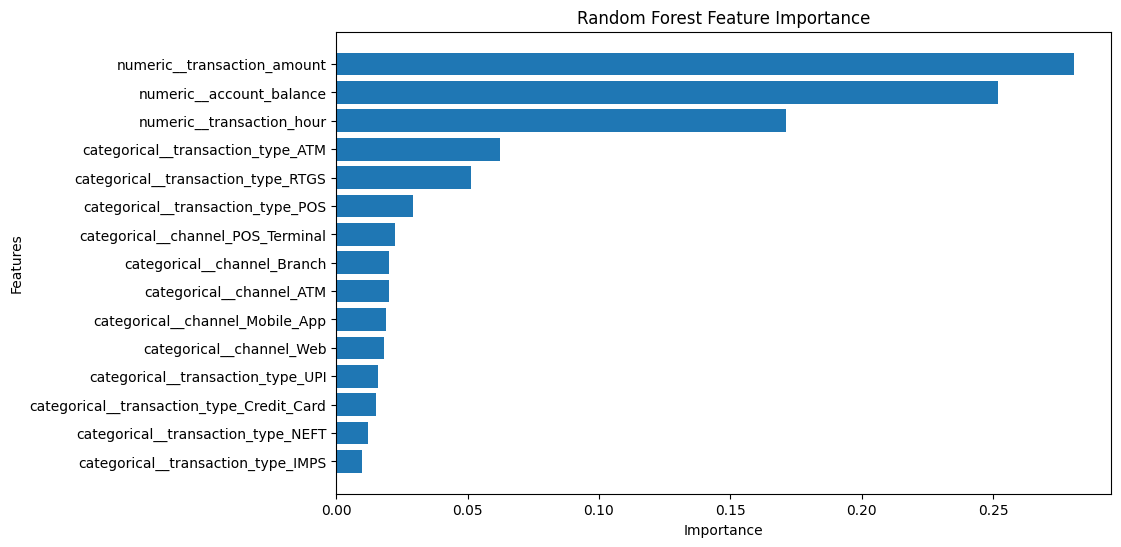

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()

plt.show()


In [ ]:
import joblib
from pathlib import Path

# Model directory
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save Logistic Regression
joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_model.pkl"
)

# Save Random Forest
joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_model.pkl"
)

print("Models saved successfully!")

print("\nSaved files:")
print(list(MODEL_DIR.glob("*.pkl")))

Models saved successfully!

Saved files:
[WindowsPath('c:/Users/KALAKANHU/Desktop/Credit-Fraud/credit2/models/logistic_model.pkl'), WindowsPath('c:/Users/KALAKANHU/Desktop/Credit-Fraud/credit2/models/random_forest_model.pkl')]


In [ ]:
import joblib

# Load saved model
loaded_rf_model = joblib.load(
    MODEL_DIR / "random_forest_model.pkl"
)

# Select one transaction
sample_transaction = X_test.iloc[[0]]

# Predict
prediction = loaded_rf_model.predict(sample_transaction)
probability = loaded_rf_model.predict_proba(sample_transaction)

print("Prediction:", prediction[0])
print("Fraud Probability:", round(probability[0][1] * 100, 2), "%")

Prediction: 0
Fraud Probability: 42.38 %


In [ ]:
fraud_probability = probability[0][1]

if prediction[0] == 1:
    print("🚨 FRAUD RISK DETECTED")
else:
    print("✅ GENUINE TRANSACTION")

print(f"Fraud Risk Score: {fraud_probability * 100:.2f}%")

✅ GENUINE TRANSACTION
Fraud Risk Score: 42.38%


In [ ]:
sample = X_test.iloc[[0]]

result = pd.DataFrame({
    "Actual": y_test.iloc[[0]].values,
    "Predicted": loaded_rf_model.predict(sample),
    "Fraud_Probability": loaded_rf_model.predict_proba(sample)[:, 1]
})

display(sample)
display(result)

,transaction_amount,transaction_hour,transaction_type,account_balance,channel
4743,2588.75,18,IMPS,72631.93,ATM


,Actual,Predicted,Fraud_Probability
0,0,0,0.423762


In [ ]:
import pandas as pd

# Create a sample transaction
new_transaction = pd.DataFrame([{
    "transaction_amount": 25000,
    "transaction_hour": 14,
    "transaction_type": "UPI",
    "account_balance": 75000,
    "channel": "Mobile_App"
}])

# Predict
prediction = loaded_rf_model.predict(new_transaction)[0]
probability = loaded_rf_model.predict_proba(new_transaction)[0][1]

# Display result
print("Transaction Details:")
display(new_transaction)

print("Prediction:", "FRAUD RISK" if prediction == 1 else "GENUINE")
print(f"Fraud Probability: {probability * 100:.2f}%")

Transaction Details:


,transaction_amount,transaction_hour,transaction_type,account_balance,channel
0,25000,14,UPI,75000,Mobile_App


Prediction: GENUINE
Fraud Probability: 46.91%


In [ ]:
test_transaction = pd.DataFrame([{
    "transaction_amount": 600000,
    "transaction_hour": 2,
    "transaction_type": "RTGS",
    "account_balance": 10000,
    "channel": "Web"
}])

pred = loaded_rf_model.predict(test_transaction)[0]
prob = loaded_rf_model.predict_proba(test_transaction)[0][1]

print("Prediction:", "FRAUD" if pred == 1 else "GENUINE")
print(f"Fraud Probability: {prob * 100:.2f}%")

Prediction: FRAUD
Fraud Probability: 56.78%
